In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

ARTIFACTS = Path("../artifacts")
RESULTS = Path("../results")

df = pd.read_csv(ARTIFACTS / "clean_data.csv")
with open(ARTIFACTS / "split_config.json") as f:
    SEED = json.load(f)["random_state"]
with open(ARTIFACTS / "best_params.json") as f:
    best_params = json.load(f)

TARGET = "CO2 uptake (mmol/g)"
FEATURES = [c for c in df.columns if c not in ["row_id", TARGET, "split"]]

train = df[df["split"] == "train"]
val = df[df["split"] == "validation"]
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(X_train.shape, X_val.shape)

MODEL_CLASSES = {
    "Random Forest":     (RandomForestRegressor,     {"random_state": SEED, "n_jobs": -1}),
    "Extra Trees":       (ExtraTreesRegressor,       {"random_state": SEED, "n_jobs": -1}),
    "Gradient Boosting": (GradientBoostingRegressor, {"random_state": SEED}),
    "XGBoost":           (XGBRegressor,              {"random_state": SEED, "n_jobs": -1}),
    "LightGBM":          (LGBMRegressor,             {"random_state": SEED, "n_jobs": -1, "verbose": -1}),
    "CatBoost":          (CatBoostRegressor,         {"random_state": SEED, "verbose": 0}),
}

def make_model(name):
    cls, fixed = MODEL_CLASSES[name]
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", cls(**best_params[name], **fixed)),
    ])

models = {name: make_model(name) for name in MODEL_CLASSES}

(336, 10) (84, 10)


In [3]:
test = df[df["split"] == "test"]
X_test, y_test = test[FEATURES], test[TARGET]

dev = df[df["split"].isin(["train", "validation"])]
X_dev, y_dev = dev[FEATURES], dev[TARGET]

with open(ARTIFACTS / "ensemble_weights.json") as f:
    weights = pd.Series(json.load(f))

def metrics(y, p):
    return {"rmse": np.sqrt(mean_squared_error(y, p)),
            "mae": mean_absolute_error(y, p),
            "r2": r2_score(y, p)}

print(X_dev.shape, X_test.shape)

(420, 10) (106, 10)


In [4]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

final_models, test_preds = {}, {}
for name in MODEL_CLASSES:
    final_models[name] = make_model(name).fit(X_dev, y_dev)
    test_preds[name] = final_models[name].predict(X_test)

ens_test = sum(weights[n] * test_preds[n] for n in weights.index)

ridge = Pipeline([("impute", SimpleImputer(strategy="median")),
                  ("scale", StandardScaler()),
                  ("model", Ridge())]).fit(X_dev, y_dev)

test_table = pd.DataFrame({
    "Ensemble (entropy-TOPSIS)": metrics(y_test, ens_test),
    "CatBoost alone":            metrics(y_test, test_preds["CatBoost"]),
    "Ridge baseline":            metrics(y_test, ridge.predict(X_test)),
}).T.round(3)
test_table

,rmse,mae,r2
Ensemble (entropy-TOPSIS),0.644,0.477,0.848
CatBoost alone,0.605,0.446,0.866
Ridge baseline,0.974,0.745,0.652


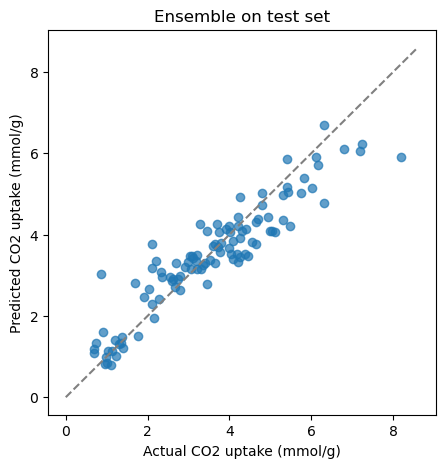

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.scatter(y_test, ens_test, alpha=0.7)
lims = [0, max(y_test.max(), ens_test.max()) * 1.05]
plt.plot(lims, lims, "--", color="gray")
plt.xlabel("Actual CO2 uptake (mmol/g)")
plt.ylabel("Predicted CO2 uptake (mmol/g)")
plt.title("Ensemble on test set")
plt.savefig(RESULTS / "07_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import joblib

joblib.dump(final_models, ARTIFACTS / "final_models.joblib")
test_table.to_csv(RESULTS / "07_test_results.csv")
print("saved")

saved
